# Лабораторная работа №1 — ноутбук 3/3: Языковое моделирование


### Библиотеки и загрузка очищенного корпуса

Сначала выполните `1_eda.ipynb`. Ноутбуки 2 и 3 используют одни и те же сохранённые Train/Test, поэтому случайное разбиение не меняется между этапами.

In [1]:
import math
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ARTIFACTS_DIR = Path("artifacts")
TRAIN_PATH = ARTIFACTS_DIR / "train_clean.csv"
TEST_PATH = ARTIFACTS_DIR / "test_clean.csv"

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Не найдены очищенные Train/Test. Сначала выполните 1_eda.ipynb."
    )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
train_seq = train_df["comment_clean"].fillna("").astype(str).map(str.split).tolist()
test_seq = test_df["comment_clean"].fillna("").astype(str).map(str.split).tolist()
RNG = np.random.default_rng(42)

print("Train:", len(train_seq), "последовательностей")
print("Test:", len(test_seq), "последовательностей")
print("Пример Train:", " ".join(train_seq[0][:45]))
assert all(seq[0] == "<s>" and seq[-1] == "</s>" for seq in train_seq[:100])
assert all(seq[0] == "<s>" and seq[-1] == "</s>" for seq in test_seq[:100])

Train: 11529 последовательностей
Test: 2883 последовательностей
Пример Train: <s> вы читали закон о банкротстве ? что бы объявить банкротом нужно обратиться в арбитражный суд с соответствующим заявлением далее суд потребует внести на свой депозит сумму обычно не менее т . р для обеспечения выплат арбитражному управляющему если сумма не вносится то в возбуждение


# 7. Биграммная языковая модель

В качестве $N$-граммной модели выбираем **$N=2$**. Её словарь формируем только на Train из `artifacts/train_clean.csv`. Редкие слова (частота меньше 2) становятся `[UNK]`; начальный `<s>` является контекстом, конечный `</s>` — предсказываемым токеном.

In [2]:
MIN_FREQ = 2
ALPHA = 0.1
all_train_counts = Counter(t for seq in train_seq for t in seq if t != "<s>")
VOCAB = ({w for w, c in all_train_counts.items() if c >= MIN_FREQ}
         | {"</s>", "[UNK]"})
VOCAB.discard("<s>")
V = len(VOCAB)

def map_unknown(seq):
    return ["<s>" if t == "<s>" else t if t in VOCAB else "[UNK]" for t in seq]

train_lm = [map_unknown(seq) for seq in train_seq]
test_lm = [map_unknown(seq) for seq in test_seq]
bigram = Counter()
context_count = Counter()
transitions = defaultdict(Counter)
for seq in train_lm:
    for ctx, nxt in zip(seq[:-1], seq[1:]):
        bigram[(ctx, nxt)] += 1
        context_count[ctx] += 1
        transitions[ctx][nxt] += 1

print("Размер словаря LM (без <s>):", V)
print("Всего биграммных событий:", sum(bigram.values()))
print("Уникальных наблюдённых биграмм:", len(bigram))
print("Частота [UNK] в обучающем корпусе:", all_train_counts.total() - sum(c for w, c in all_train_counts.items() if w in VOCAB))
print("Пример из Test с заменой OOV:", " ".join(test_lm[0][:35]))
assert all(t == "<s>" or t in VOCAB for seq in test_lm for t in seq)

Размер словаря LM (без <s>): 22362
Всего биграммных событий: 360050
Уникальных наблюдённых биграмм: 176004
Частота [UNK] в обучающем корпусе: 36659
Пример из Test с заменой OOV: <s> [UNK] . для этого нужно придумать [UNK] силы . а для этого нужно как минимум знать какие силы [UNK] а какие нет . а зачем ? вон в [UNK] верили что если сделать [UNK]


In [3]:
top_bigrams = pd.DataFrame([
    {'предыдущее слово': a, 'следующее слово': b, 'частота': n,
     'P(слово | контекст)': round(n / context_count[a], 5)}
    for (a, b), n in bigram.most_common(20)
])
print('Самые частые биграммы Train:')
display(top_bigrams)
if len(top_bigrams):
    row = top_bigrams.iloc[0]
    print(f'Пример: P({row["следующее слово"]} | {row["предыдущее слово"]}) = '
          f'{bigram_probability(row["предыдущее слово"],row["следующее слово"],0) if "bigram_probability" in globals() else row["P(слово | контекст)"]:.4f}')

Самые частые биграммы Train:


,предыдущее слово,следующее слово,частота,P(слово | контекст)
0,.,</s>,6026,0.26487
1,[UNK],[UNK],5034,0.13732
2,[UNK],.,4148,0.11315
3,[UNK],и,1863,0.05082
4,и,[UNK],1608,0.15802
5,в,[UNK],1350,0.14065
6,?,</s>,1350,0.35193
7,[UNK],в,1215,0.03314
8,не,[UNK],1174,0.14317
9,.,[UNK],1034,0.04545


Пример: P(</s> | .) = 0.2649


# 8. Сглаживание и перплексия

Для неизвестных биграмм несглаженная вероятность нулевая. Проверяем **разные значения аддитивного сглаживания** на заранее отложенной тестовой выборке. Значение $+\infty$ для перплексии при $\alpha=0$ не является технической ошибкой — это математическое следствие нулевой вероятности.

In [4]:
def bigram_probability(ctx, nxt, alpha=0.0):
    if alpha == 0:
        return bigram[(ctx, nxt)] / context_count[ctx] if context_count[ctx] else 0.0
    return (bigram[(ctx, nxt)] + alpha) / (context_count[ctx] + alpha * V)


def corpus_perplexity(sequences, alpha=0.0):
    log_likelihood = 0.0
    events, zeros = 0, 0
    for seq in sequences:
        for ctx, nxt in zip(seq[:-1], seq[1:]):
            events += 1
            p = bigram_probability(ctx, nxt, alpha)
            if p == 0:
                zeros += 1
            else:
                log_likelihood += math.log(p)
    ppl = math.inf if zeros else math.exp(-log_likelihood / events)
    return {"alpha": alpha, "perplexity": ppl,
            "токенов в Test": events, "нулевых вероятностей": zeros,
            "доля неизвестных биграмм, %": round(100 * zeros / events, 2)}

ppl_table = pd.DataFrame([corpus_perplexity(test_lm, alpha=a) for a in (0.0, 0.1, 1.0)])
display(ppl_table)

assert bigram_probability("<s>", "</s>", alpha=0.1) > 0
assert bigram_probability("<s>", "[UNK]", alpha=0.1) > 0

,alpha,perplexity,токенов в Test,нулевых вероятностей,"доля неизвестных биграмм, %"
0,0.0,inf,89721,28490,31.75
1,0.1,1090.203872,89721,0,0.00
2,1.0,2332.493214,89721,0,0.00


In [5]:
base = ppl_table.iloc[0]
print(f"Несглаженная биграммная LM на Test: {int(base['нулевых вероятностей'])} "
      f"нулевых вероятностей из {int(base['токенов в Test'])} событий.")
if np.isinf(base["perplexity"]):
    print("PPL без сглаживания = +∞ (хотя бы одна тестовая биграмма не наблюдалась в Train).")
else:
    print(f"PPL без сглаживания = {base['perplexity']:.2f}; в этой выборке все тестовые биграммы наблюдались.")
for _, row in ppl_table.iloc[1:].iterrows():
    print(f"Add-alpha={row['alpha']}: PPL={row['perplexity']:.2f} "
          "— все условные вероятности строго положительны.")

Несглаженная биграммная LM на Test: 28490 нулевых вероятностей из 89721 событий.
PPL без сглаживания = +∞ (хотя бы одна тестовая биграмма не наблюдалась в Train).
Add-alpha=0.1: PPL=1090.20 — все условные вероятности строго положительны.
Add-alpha=1.0: PPL=2332.49 — все условные вероятности строго положительны.


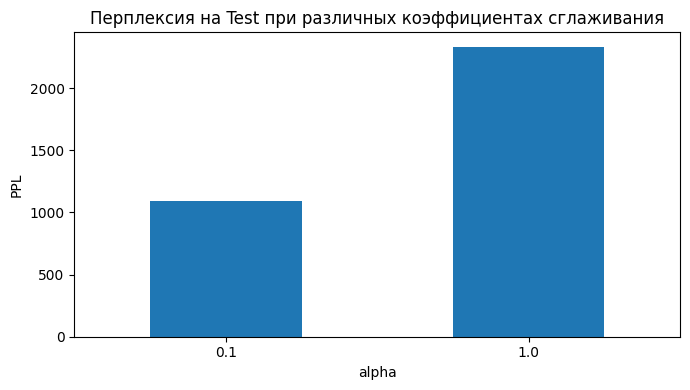

In [6]:
finite_scores = ppl_table.loc[np.isfinite(ppl_table['perplexity'])].copy()
if len(finite_scores):
    ax = finite_scores.plot.bar(x='alpha', y='perplexity', legend=False, rot=0, figsize=(7, 4))
    ax.set(title='Перплексия на Test при различных коэффициентах сглаживания', ylabel='PPL', xlabel='alpha')
    plt.tight_layout(); plt.show()
else:
    print('Нет конечных значений PPL для построения графика.')

# 9. Генерация текстов Марковской цепью

Генерируем пять отдельных последовательностей из реальных наблюдавшихся переходов биграммной модели; генерация заканчивается при `</s>` или по ограничению длины. Короткий контекст ограничивает связность и не гарантирует грамматически правильный текст.

In [ ]:

def generate_bigram(rng, max_tokens=55):
    result = ["<s>"]
    for _ in range(max_tokens):
        options = transitions.get(result[-1])
        if not options:
            break
        choices, counts = zip(*[(token, c) for token, c in options.items() if token != "<s>"])
        weights = np.asarray(counts, dtype=float)
        nxt = choices[int(rng.choice(len(choices), p=weights / weights.sum()))]
        result.append(nxt)
        if nxt == "</s>":
            break
    return result

for idx in range(1, 6):
    seq = generate_bigram(RNG)
    print(f"Текст {idx} ({'завершён' if seq[-1] == '</s>' else 'достигнут лимит/нет перехода'}):")
    print(" ".join(seq))
    print()

Текст 1 (завершён):
<s> боже и поступают так что светодиоды стоят ? </s>

Текст 2 (достигнут лимит/нет перехода):
<s> это реклама ? это остановился или не о том какой рост цен в вс равно только [UNK] сразу же . [NUM] см поднимется вопрос об этом плане литературы издателй всё будет забавно да чёт сомневаюсь что говно из них электроэнергию по [UNK] [UNK] располагался светодиод . такие магазины приезжают мы должны будут то не взять

Текст 3 (завершён):
<s> ащущенее [UNK] действительно [UNK] [UNK] и даже [UNK] боюсь до сих пор . однако ему пора . а о [UNK] [UNK] [UNK] успела [UNK] на земле бродит в любом случае новое придумают фильтр . </s>

Текст 4 (завершён):
<s> сдавали бутылки [UNK] . чего-то начать обучать это моя [UNK] пидорашки же такие в аварийном состоянии [UNK] пользуются данным до человека [UNK] мой взгляд . </s>

Текст 5 (завершён):
<s> не особо [UNK] [UNK] было определить на современные государства является [UNK] станцию а уровень [UNK] ? где стоит [UNK] ? </s>



# 10. Итоги работы


In [8]:
summary_rows = []

for summary_file in ("eda_summary.csv", "metrics_summary.csv"):
    summary_path = ARTIFACTS_DIR / summary_file
    if summary_path.exists():
        part = pd.read_csv(summary_path)
        summary_rows.extend(part[["Показатель", "Значение"]].itertuples(index=False, name=None))

summary_rows.extend([
    ("Размер словаря биграммной модели", V),
    ("Количество наблюдавшихся биграмм", len(bigram)),
    ("PPL без сглаживания", ppl_table.loc[ppl_table["alpha"] == 0.0, "perplexity"].iloc[0]),
    ("PPL Add-0.1", ppl_table.loc[ppl_table["alpha"] == 0.1, "perplexity"].iloc[0]),
    ("PPL Add-1", ppl_table.loc[ppl_table["alpha"] == 1.0, "perplexity"].iloc[0]),
])
summary = pd.DataFrame(summary_rows, columns=["Показатель", "Значение"])
display(summary)
summary.to_csv(ARTIFACTS_DIR / "lab1_final_summary.csv", index=False, encoding="utf-8")
print("Итоговая сводка сохранена:", (ARTIFACTS_DIR / "lab1_final_summary.csv").resolve())

,Показатель,Значение
0,Объём Train,1.152900e+04
1,Объём Test,2.883000e+03
2,"Средняя длина Train, слов",2.734000e+01
3,"Средняя длина Train, символов",1.767100e+02
4,"Типов шума, обнаруженных в Train",5.000000e+00
5,Уникальных слов до нормализации,5.901300e+04
6,Уникальных слов после стемминга,2.950300e+04
7,Уникальных слов после лемматизации,3.078000e+04
8,Кандидатных пар Левенштейна (d=1 или 2),7.439000e+03
9,Размер словаря биграммной модели,2.236200e+04


Итоговая сводка сохранена: D:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\artifacts\lab1_final_summary.csv


Вывод

В ходе лабораторной работы был проведён анализ датасета русскоязычных комментариев. Данные разделены на обучающую (11 529) и тестовую (2 883) выборки. Средняя длина комментария составила 27,34 слова. Обнаружено 5 типов текстового шума.

Стемминг и лемматизация позволили сократить словарь с 59 013 до 29 503 и 30 780 уникальных слов соответственно. Также найдено 7 439 кандидатных пар слов с расстоянием Левенштейна не более 2.

Для биграммной модели лучшая перплексия получена при Add-0.1 (1090,20), тогда как при Add-1 она составила 2332,49. Без сглаживания перплексия бесконечна из-за нулевых вероятностей невстречавшихся биграмм.

Таким образом, были изучены основные методы предобработки текстов и построения статистической языковой модели.